In [ ]:
!pip uninstall -y torch torchvision torchaudio trl accelerate transformers
!pip install torch==2.4.1 --index-url https://download.pytorch.org/whl/cu121
!pip install transformers==4.44.2 accelerate==0.34.2 trl==0.10.1 peft datasets

# Traditional RLHF via Proximal Policy Optimization (PPO)
**Model:** `facebook/opt-125m` | **Dataset:** `argilla/ultrafeedback`

## Overview
As per the assignment baseline requirements, this notebook implements a traditional Reinforcement Learning with Human Feedback (RLHF) pipeline using Proximal Policy Optimization (PPO).

While subsequent notebooks in this project explore Direct Preference Optimization (DPO) to circumvent hardware bottlenecks and training instability, this notebook establishes the standard PPO baseline for methodological comparison.

## Pipeline Stages
1. **Supervised Fine-Tuning (SFT):** Sourced from the baseline Alpaca tuning phase.
2. **Reward Modeling:** Training a discrete sequence classification model (`trl.RewardTrainer`) on human preference data to output scalar reward values.
3. **PPO Optimization:** Utilizing the trained Reward Model alongside a Value Head to optimize the SFT policy model via `trl.PPOTrainer`.

In [ ]:
import torch
import os
import shutil
import json
from datasets import load_dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer, pipeline, AutoModelForCausalLM
from peft import LoraConfig, get_peft_model, PeftModel
from google.colab import drive
from trl import PPOTrainer, PPOConfig, AutoModelForCausalLMWithValueHead, RewardConfig, RewardTrainer
from tqdm import tqdm
import matplotlib.pyplot as plt

In [ ]:
# Mount Drive
drive.mount('/content/drive')
BASE_DIR = "/content/drive/MyDrive/RLHF_Project"
os.makedirs(BASE_DIR, exist_ok=True)

model_id = "facebook/opt-125m"

# WE TRAIN ON LOCAL DISK TO BYPASS GOOGLE DRIVE SYNC BUGS
local_rm_dir = "/content/opt_reward_model"
final_drive_dir = os.path.join(BASE_DIR, "opt_reward_model")

tokenizer = AutoTokenizer.from_pretrained(model_id)
tokenizer.pad_token = tokenizer.eos_token

print("--- Preparing Reward Model Dataset ---")
def preprocess_rm(example):
    prompt = example["prompt"][0]["content"] if isinstance(example["prompt"], list) else example["prompt"]
    chosen = example["chosen"][-1]["content"] if isinstance(example["chosen"], list) else example["chosen"]
    rejected = example["rejected"][-1]["content"] if isinstance(example["rejected"], list) else example["rejected"]

    tokenized_chosen = tokenizer(prompt + "\n" + chosen, truncation=True, max_length=512)
    tokenized_rejected = tokenizer(prompt + "\n" + rejected, truncation=True, max_length=512)

    return {
        "input_ids_chosen": tokenized_chosen["input_ids"],
        "attention_mask_chosen": tokenized_chosen["attention_mask"],
        "input_ids_rejected": tokenized_rejected["input_ids"],
        "attention_mask_rejected": tokenized_rejected["attention_mask"],
    }

# 10,000 samples to precisely match your DPO methodology
ds = load_dataset("argilla/ultrafeedback-binarized-preferences-cleaned", split="train[:10000]")
ds = ds.map(preprocess_rm, batched=False)
ds = ds.filter(lambda x: len(x["input_ids_chosen"]) <= 512 and len(x["input_ids_rejected"]) <= 512)
ds_split = ds.train_test_split(test_size=0.1)

print("--- Initializing Reward Model ---")
rm_model = AutoModelForSequenceClassification.from_pretrained(model_id, num_labels=1, device_map="auto")
rm_model.config.pad_token_id = tokenizer.pad_token_id

peft_config = LoraConfig(task_type="SEQ_CLS", r=8, lora_alpha=16, target_modules=["q_proj", "v_proj"])
rm_model = get_peft_model(rm_model, peft_config)

rm_config = RewardConfig(
    output_dir=local_rm_dir,
    per_device_train_batch_size=16,
    gradient_accumulation_steps=2,
    learning_rate=1e-5,
    num_train_epochs=1,
    logging_steps=10,
    eval_strategy="steps",
    eval_steps=50,
    save_steps=500,
    remove_unused_columns=False
)

trainer = RewardTrainer(
    model=rm_model,
    tokenizer=tokenizer,
    args=rm_config,
    train_dataset=ds_split["train"],
    eval_dataset=ds_split["test"],
)

print("--- Training Reward Model ---")
trainer.train()

print("--- Saving to Local Disk ---")
trainer.save_model(local_rm_dir)

print("--- Safely Copying Finished Model to Google Drive ---")
if os.path.exists(final_drive_dir):
    shutil.rmtree(final_drive_dir) # Nuke any old corrupted versions
shutil.copytree(local_rm_dir, final_drive_dir)

In [ ]:
BASE_DIR = "/content/drive/MyDrive/RLHF_Project"
sft_model_id = os.path.join(BASE_DIR, "opt_sft_final_model")
ppo_output_dir = os.path.join(BASE_DIR, "opt_ppo_final")
rm_output_dir = os.path.join(BASE_DIR, "opt_reward_model")

# Load Tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_id)
tokenizer.pad_token = tokenizer.eos_token

print("--- Loading Policy and Reference Models ---")
ppo_model = AutoModelForCausalLMWithValueHead.from_pretrained(sft_model_id)
ppo_model_ref = AutoModelForCausalLMWithValueHead.from_pretrained(sft_model_id)

print("--- Loading Reward Pipeline ---")
base_rm = AutoModelForSequenceClassification.from_pretrained(model_id, num_labels=1)
base_rm.config.pad_token_id = tokenizer.pad_token_id

rm_model_for_pipe = PeftModel.from_pretrained(base_rm, rm_output_dir)
# device=0 automatically and safely maps the RM to the GPU for inference
reward_pipe = pipeline("text-classification", model=rm_model_for_pipe, tokenizer=tokenizer, device=0)

print("--- Preparing Dataset ---")
def build_ppo_dataset():
    # 10,000 PPO prompts (strictly separated from the RM's training data)
    ds_ppo = load_dataset("argilla/ultrafeedback-binarized-preferences-cleaned", split="train[10000:20000]")

    def extract_prompt(example):
        prompt = example["prompt"][0]["content"] if isinstance(example["prompt"], list) else example["prompt"]
        return {"query": prompt, "input_ids": tokenizer.encode(prompt, truncation=True, max_length=256)}

    ds_ppo = ds_ppo.map(extract_prompt, batched=False)
    ds_ppo.set_format(type="torch", columns=["input_ids", "query"])
    return ds_ppo

ppo_dataset = build_ppo_dataset()

def collator(data):
    return dict((key, [d[key] for d in data]) for key in data[0])

ppo_config = PPOConfig(
    learning_rate=1.41e-5,
    batch_size=32,
    mini_batch_size=8,
    gradient_accumulation_steps=2,
    optimize_cuda_cache=True
)

ppo_trainer = PPOTrainer(
    config=ppo_config,
    model=ppo_model,
    ref_model=ppo_model_ref,
    tokenizer=tokenizer,
    dataset=ppo_dataset,
    data_collator=collator
)

generation_kwargs = {
    "min_length": -1,
    "top_k": 0.0,
    "top_p": 1.0,
    "do_sample": True,
    "pad_token_id": tokenizer.pad_token_id,
    "max_new_tokens": 64
}

tracked_rewards = []

print("--- Starting PPO Training Loop ---")
for epoch, batch in tqdm(enumerate(ppo_trainer.dataloader)):
    query_tensors = batch["input_ids"]

    # Generate model responses
    response_tensors = ppo_trainer.generate(query_tensors, return_prompt=False, **generation_kwargs)
    batch["response"] = [tokenizer.decode(r.squeeze()) for r in response_tensors]

    # Calculate reward scores using the pipeline
    texts = [q + r for q, r in zip(batch["query"], batch["response"])]
    pipe_outputs = reward_pipe(texts, batch_size=8, truncation=True, max_length=512)

    # Safely parse pipeline output and map to the active GPU
    rewards = []
    for output in pipe_outputs:
        score = output[0]["score"] if isinstance(output, list) else output["score"]
        rewards.append(torch.tensor(score).to(ppo_trainer.accelerator.device))

    # Store the average reward of this batch to plot later
    mean_reward = torch.stack(rewards).mean().item()
    tracked_rewards.append(mean_reward)

    # Update the policy weights.
    stats = ppo_trainer.step(query_tensors, response_tensors, rewards)
    ppo_trainer.log_stats(stats, batch, rewards)

print("--- Saving Finished PPO Model ---")
ppo_trainer.save_pretrained(ppo_output_dir)

# Save JSON directly to Google Drive so it isn't lost if Colab disconnects
with open(os.path.join(BASE_DIR, "ppo_rewards.json"), "w") as f:
    json.dump(tracked_rewards, f)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


--- Loading Policy and Reference Models ---
--- Loading Reward Pipeline ---


Some weights of OPTForSequenceClassification were not initialized from the model checkpoint at facebook/opt-125m and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The model 'PeftModelForSequenceClassification' is not supported for text-classification. Supported models are ['AlbertForSequenceClassification', 'BartForSequenceClassification', 'BertForSequenceClassification', 'BigBirdForSequenceClassification', 'BigBirdPegasusForSequenceClassification', 'BioGptForSequenceClassification', 'BloomForSequenceClassification', 'CamembertForSequenceClassification', 'CanineForSequenceClassification', 'LlamaForSequenceClassification', 'ConvBertForSequenceClassification', 'CTRLForSequenceClassification', 'Data2VecTextForSequenceClassification', 'DebertaForSequenceClassification', 'DebertaV2ForSequenceClassification', 'DistilBertForSequenceClassification', 'ElectraForSequenceClassification', 'Erni

--- Preparing Dataset ---
--- Starting PPO Training Loop ---


0it [00:00, ?it/s]You're using a GPT2TokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.
10it [01:33,  9.28s/it]You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset
27it [03:52,  6.33s/it]/usr/local/lib/python3.12/dist-packages/trl/trainer/ppo_trainer.py:1238: UserWarning: The average ratio of batch (18.65) exceeds threshold 10.00. Skipping batch.
  warnings.warn(
33it [04:18,  4.65s/it]/usr/local/lib/python3.12/dist-packages/trl/trainer/ppo_trainer.py:1238: UserWarning: The average ratio of batch (19.71) exceeds threshold 10.00. Skipping batch.
  warnings.warn(
37it [04:34,  3.98s/it]/usr/local/lib/python3.12/dist-packages/trl/trainer/ppo_trainer.py:1238: UserWarning: The average ratio of batch (11.63) exceeds threshold 10.00. Skipping batch.
  warnings.warn(
38it [04:38,  3.92

--- Saving Finished PPO Model ---


AttributeError: 'PPOTrainer' object has no attribute 'save_model'

/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


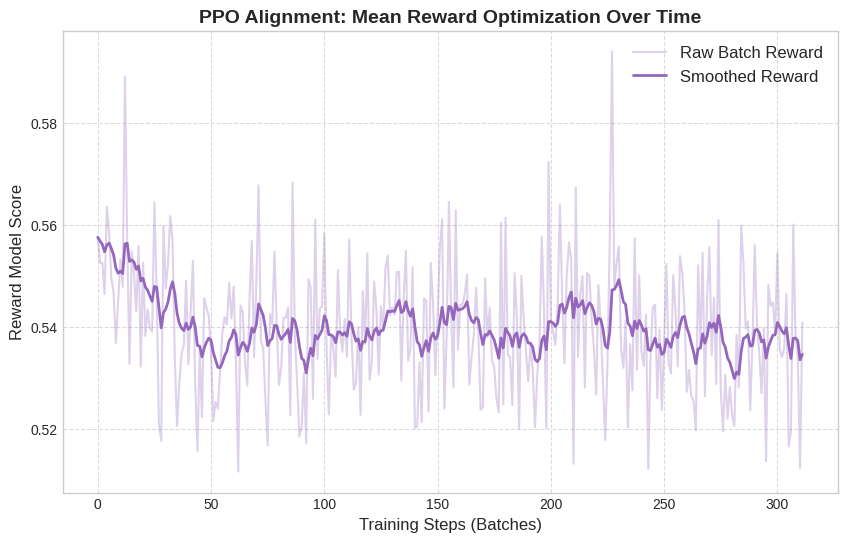

Some weights of the model checkpoint at /content/drive/MyDrive/RLHF_Project/opt_ppo_final were not used when initializing OPTForCausalLM: ['v_head.summary.bias', 'v_head.summary.weight']
- This IS expected if you are initializing OPTForCausalLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing OPTForCausalLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Graph saved for Overleaf at: /content/drive/MyDrive/RLHF_Project/ppo_reward_curve.png

 PPO QUALITATIVE EVALUATION 

PROMPT: What are the benefits of a healthy diet?
--------------------------------------------------
PPO Output:
What are the benefits of a healthy diet?


In [ ]:
ppo_output_dir = os.path.join(BASE_DIR, "opt_ppo_final")
tokenizer = AutoTokenizer.from_pretrained("facebook/opt-125m")

# 1. Plot the PPO Reward Curve (Reading safely from Google Drive)
rewards_path = os.path.join(BASE_DIR, "ppo_rewards.json")
with open(rewards_path, "r") as f:
    tracked_rewards = json.load(f)

plt.figure(figsize=(10, 6))
plt.style.use('seaborn-v0_8-whitegrid')

# Smoothing the curve to make it look clean for the report
def smooth(scalars, weight=0.85):
    last = scalars[0]
    smoothed = []
    for point in scalars:
        smoothed_val = last * weight + (1 - weight) * point
        smoothed.append(smoothed_val)
        last = smoothed_val
    return smoothed

plt.plot(tracked_rewards, alpha=0.3, color='#9467bd', label='Raw Batch Reward')
plt.plot(smooth(tracked_rewards), linewidth=2, color='#9467bd', label='Smoothed Reward')

plt.title("PPO Alignment: Mean Reward Optimization Over Time", fontsize=14, fontweight='bold')
plt.xlabel("Training Steps (Batches)", fontsize=12)
plt.ylabel("Reward Model Score", fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

plot_path = os.path.join(BASE_DIR, "ppo_reward_curve.png")
plt.savefig(plot_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Graph saved for Overleaf at: {plot_path}")

# 2. Qualitative Sanity Check
print("\n" + "="*50)
print(" PPO QUALITATIVE EVALUATION ")
print("="*50)

ppo_pipe = pipeline("text-generation", model=ppo_output_dir, tokenizer=tokenizer, device=0)

prompt = "What are the benefits of a healthy diet?"
fmt_prompt = f"### Instruction:\n{prompt}\n\n### Response:\n"

gen_kwargs = {"max_new_tokens": 75, "do_sample": True, "temperature": 0.7, "top_p": 0.9, "return_full_text": False}

print(f"\nPROMPT: {prompt}")
print("-" * 50)
print(f"PPO Output:\n{ppo_pipe(fmt_prompt, **gen_kwargs)[0]['generated_text'].strip()}")

In [ ]:
print("--- Calculating PPO Perplexity ---")
# Load the saved PPO model as a standard Causal LM for pure text evaluation
eval_model = AutoModelForCausalLM.from_pretrained(ppo_output_dir, device_map={"": 0})
eval_model.eval()

test = load_dataset("wikitext", "wikitext-2-raw-v1", split="test[:50]")
encodings = tokenizer("\n\n".join(test["text"]), return_tensors="pt")

max_length = eval_model.config.max_position_embeddings
stride = 512
seq_len = encodings.input_ids.size(1)

nlls = []
for i in tqdm(range(0, seq_len, stride)):
    begin_loc = max(i + stride - max_length, 0)
    end_loc = min(i + stride, seq_len)
    trg_len = end_loc - i
    input_ids = encodings.input_ids[:, begin_loc:end_loc].to(eval_model.device)
    target_ids = input_ids.clone()
    target_ids[:, :-trg_len] = -100

    with torch.no_grad():
        outputs = eval_model(input_ids, labels=target_ids)
        neg_log_likelihood = outputs.loss

    nlls.append(neg_log_likelihood)

ppl = torch.exp(torch.stack(nlls).mean())
print(f"\nPPO Perplexity: {ppl.item():.2f}")

--- Calculating PPO Perplexity ---


Some weights of the model checkpoint at /content/drive/MyDrive/RLHF_Project/opt_ppo_final were not used when initializing OPTForCausalLM: ['v_head.summary.bias', 'v_head.summary.weight']
- This IS expected if you are initializing OPTForCausalLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing OPTForCausalLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


README.md: 0.00B [00:00, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…):   0%|          | 0.00/733k [00:00<?, ?B/s]

wikitext-2-raw-v1/train-00000-of-00001.p(…):   0%|          | 0.00/6.36M [00:00<?, ?B/s]

...

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

100%|██████████| 5/5 [00:00<00:00, 21.02it/s]


PPO Perplexity: 61.76
